# Bitcoin hourly forecasting with Prophet

This experiment aggregates minute-level BTC prices to hours and compares forecasts with separate validation and test periods. Place `btcusd_1-min_data.csv` in `lesson_30/` before running. Dependencies include pandas, NumPy, Matplotlib, and Prophet.

The split uses disjoint chronological training, validation and test periods. Forecasts are exploratory and do not establish trading performance.

BTC source: [Bitcoin Historical Data](https://www.kaggle.com/datasets/mczielinski/bitcoin-historical-data). Dataset updates may change the date range and results.

**Data:** [Bitcoin Historical Data](https://www.kaggle.com/datasets/mczielinski/bitcoin-historical-data). Set `BTC_DATA_PATH` to `btcusd_1-min_data.csv`, or put it in `lesson_30/`. The dataset changes over time.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

hourly = pd.DataFrame()

hourly = pd.read_csv(os.environ.get('BTC_DATA_PATH', '../lesson_30/btcusd_1-min_data.csv'))
hourly['Timestamp'] = pd.to_datetime(hourly['Timestamp'], unit='s', utc=True)
hourly = hourly.set_index('Timestamp')

hourly = hourly.resample('h').agg({
    'Open': 'first',
    'High': 'max',
    'Low': 'min',
    'Close': 'last',
    'Volume': 'sum'
})

print(f"Начало: {hourly.index.min()}")
print(f"Конец: {hourly.index.max()}")
print(f"Количество строк: {len(hourly)}")
print(f"\nПервые несколько строк:")
print(hourly.head())
print(f"\nИнформация о типах данных:")
print(hourly.dtypes)


Начало: 2012-01-01 00:00:00+00:00
Конец: 2026-11-06 04:00:00+00:00
Количество строк: 130157

Первые несколько строк:
                           Open  High   Low  Close  Volume
Timestamp                                                 
2012-01-01 00:00:00+00:00  4.58  4.58  4.58   4.58   0.000
2012-01-01 01:00:00+00:00  4.58  4.58  4.58   4.58   0.000
2012-01-01 02:00:00+00:00  4.58  4.58  4.58   4.58   0.000
2012-01-01 03:00:00+00:00  4.58  4.58  4.58   4.58   0.000
2012-01-01 04:00:00+00:00  4.58  4.58  4.58   4.58   1.502

Информация о типах данных:
Open      float64
High      float64
Low       float64
Close     float64
Volume    float64
dtype: object


In [2]:
print(hourly.isna().sum())

Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [3]:
hourly = hourly.ffill()

Text(0.5, 0, 'Год')

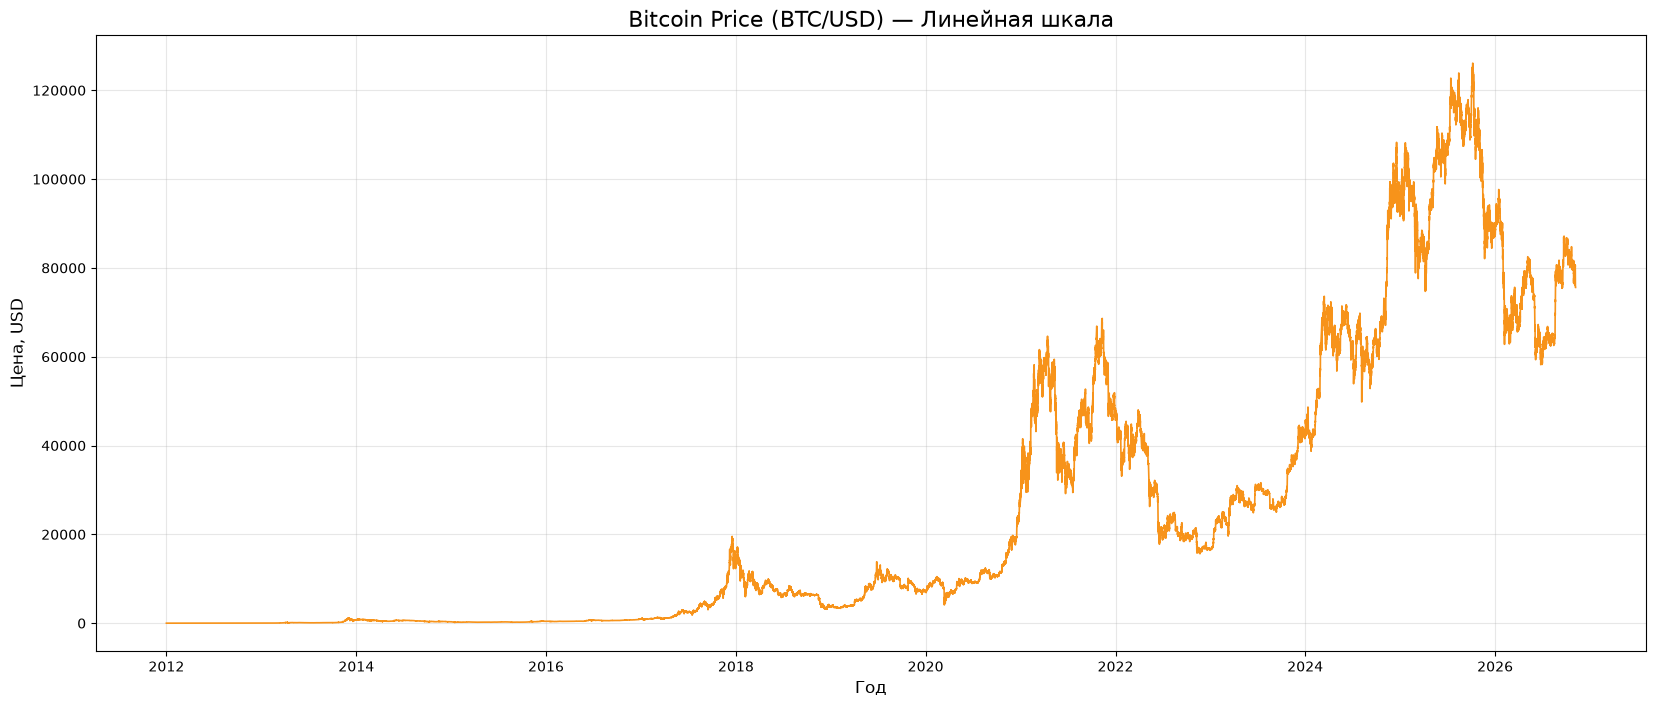

In [4]:
plt.figure(figsize=(20, 8))
plt.plot(hourly.index, hourly['Close'], color='#f7931a', linewidth=1.2)
plt.title(f'Bitcoin Price (BTC/USD) — Линейная шкала', fontsize=16)
plt.ylabel('Цена, USD', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xlabel('Год', fontsize=12)

Prophet основана на аддитивной модели временных рядов (additive model), которая разбивает ряд на независимые компоненты. Основная формула модели:
![](img/img_1.png)


Модель обучается с помощью байесовского вывода (Bayesian inference), что позволяет учитывать priors (априорные распределения) для параметров и генерировать интервалы неопределенности (например, 80% или 95% доверительные интервалы)

Тренд (g(t)):
Prophet моделирует тренд как piecewise linear (кусочно-линейный)
![](img/img_2.png)

Сезонность (s(t)):
![](img/img_3.png)

Праздники и события (h(t)):
![](img/img_4.png)

Ошибка epsilon_{t} содержит информацию, которая не учтена моделью


In [5]:
import numpy as np

print(f"\nСтатистика по Close:")
print(hourly['Close'].describe())

print(f"\nБесконечные значения в Close: {(hourly['Close'] == np.inf).sum()}")
print(f"Отрицательные значения в Close: {(hourly['Close'] <= 0).sum()}")



Статистика по Close:
count    130157.000000
mean      24659.876664
std       31905.963559
min           4.140000
25%         476.580000
50%        8346.670000
75%       41789.000000
max      126111.000000
Name: Close, dtype: float64

Бесконечные значения в Close: 0
Отрицательные значения в Close: 0


In [6]:
from prophet import Prophet
from datetime import timedelta
import matplotlib.pyplot as plt

last_ts = hourly.index[-1]
print(f"Последняя точка в данных: {last_ts} UTC")

test_start = last_ts - timedelta(days=7)
val_start = test_start - timedelta(days=7)

train_df = hourly.loc[hourly.index < val_start]
val_df = hourly.loc[(hourly.index >= val_start) & (hourly.index < test_start)]
test_df = hourly.loc[hourly.index >= test_start]

print(f"Train      : {train_df.index[0].date()} -> {train_df.index[-1].date()}    ({len(train_df)} точек)")
print(f"Validation : {val_df.index[0].date()} -> {val_df.index[-1].date()}    ({len(val_df)} точек)")
print(f"Test       : {test_df.index[0].date()} -> {test_df.index[-1].date()}    ({len(test_df)} точек)")

Последняя точка в данных: 2026-11-06 04:00:00+00:00 UTC
Train      : 2012-01-01 -> 2026-10-23    (129820 точек)
Validation : 2026-10-23 -> 2026-10-30    (168 точек)
Test       : 2026-10-30 -> 2026-11-06    (169 точек)


In [7]:
train_ph = train_df[['Close']].reset_index().rename(columns={'Timestamp': 'ds', 'Close': 'y'})
val_ph   = val_df[['Close']].reset_index().rename(columns={'Timestamp': 'ds', 'Close': 'y'})
test_ph  = test_df[['Close']].reset_index().rename(columns={'Timestamp': 'ds', 'Close': 'y'})

train_ph['ds'] = train_ph['ds'].dt.tz_convert(None)
val_ph['ds']   = val_ph['ds'].dt.tz_convert(None)
test_ph['ds']  = test_ph['ds'].dt.tz_convert(None)

In [8]:
model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True,
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=10.0
)
model.add_country_holidays(country_name='US')

model.fit(train_ph)

~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


14:41:25 - cmdstanpy - INFO - Chain [1] start processing


14:42:13 - cmdstanpy - INFO - Chain [1] done processing


In [9]:
def print_error(df_real, name):
    future_temp = pd.concat([train_ph[['ds']], df_real[['ds']]]).drop_duplicates()
    forecast = model.predict(future_temp)
    merged = df_real.merge(forecast[['ds', 'yhat']], on='ds')
    mae  = abs(merged['y'] - merged['yhat']).mean()
    mape = 100 * abs((merged['y'] - merged['yhat']) / merged['y']).mean()
    print(f"{name:11} → MAE = ${mae:,.0f}   |   MAPE = {mape:.2f}%")

print("\nКачество модели:")
print_error(val_ph,  "Validation")
print_error(test_ph, "Test")


Качество модели:


Validation  → MAE = $16,845   |   MAPE = 20.96%


Test        → MAE = $20,364   |   MAPE = 26.22%


In [10]:
val_ph_plot = val_ph.copy()
test_ph_plot = test_ph.copy()
val_ph_plot['ds'] = pd.to_datetime(val_ph['ds']).dt.tz_localize('UTC')
test_ph_plot['ds'] = pd.to_datetime(test_ph['ds']).dt.tz_localize('UTC')

forecast_val = model.predict(val_ph[['ds']])
forecast_test = model.predict(test_ph[['ds']])

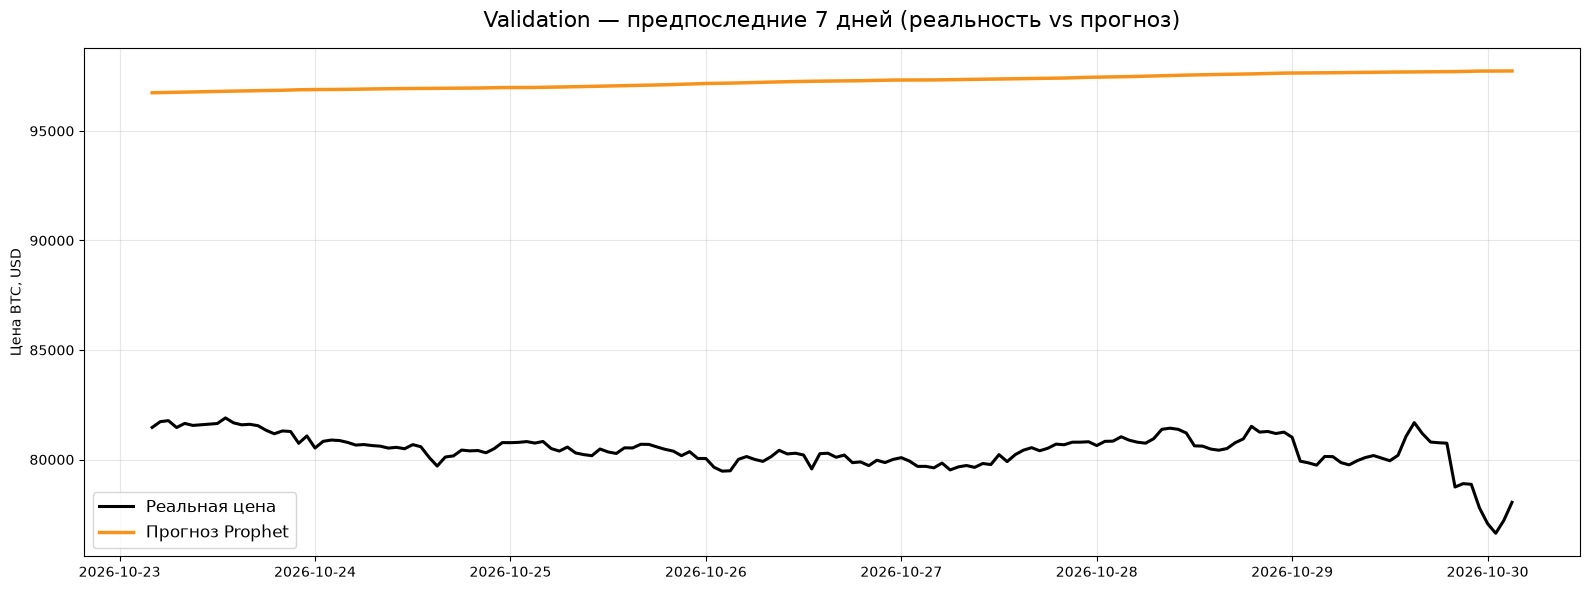

In [11]:
plt.figure(figsize=(16, 6))
plt.plot(val_ph_plot['ds'], val_ph_plot['y'],    color='black',     linewidth=2.2, label='Реальная цена')
plt.plot(val_ph_plot['ds'], forecast_val['yhat'], color='#f7931a', linewidth=2.5, label='Прогноз Prophet')

plt.title('Validation — предпоследние 7 дней (реальность vs прогноз)', fontsize=16, pad=15)
plt.ylabel('Цена BTC, USD')
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()